In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rating=pd.read_csv("Data/ratings.csv")
movie=pd.read_csv("Data/movies.csv")
print(rating)
print(movie)


        userId  movieId  rating   timestamp
0            1        1     4.0   964982703
1            1        3     4.0   964981247
2            1        6     4.0   964982224
3            1       47     5.0   964983815
4            1       50     5.0   964982931
...        ...      ...     ...         ...
100831     610   166534     4.0  1493848402
100832     610   168248     5.0  1493850091
100833     610   168250     5.0  1494273047
100834     610   168252     5.0  1493846352
100835     610   170875     3.0  1493846415

[100836 rows x 4 columns]
      movieId                                      title  \
0           1                           Toy Story (1995)   
1           2                             Jumanji (1995)   
2           3                    Grumpier Old Men (1995)   
3           4                   Waiting to Exhale (1995)   
4           5         Father of the Bride Part II (1995)   
...       ...                                        ...   
9737   193581  Black Butl

In [2]:
#database statistics
nusers=rating.userId.nunique()
nmovies=rating.movieId.nunique()  # only movies that have at least one rating
nrating=len(rating.rating)
Sparsity=(1-(nrating/(nusers*nmovies)))*100
print(nusers,nmovies,nrating,Sparsity)

610 9724 100836 98.30003169443864


In [3]:
#Make a User-Item Matrix
rating_matrix = rating.pivot(
    index="userId",
    columns="movieId",
    values="rating"
)

rating_matrix

movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,2.5,NaN,NaN,NaN,NaN,NaN,2.5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
607,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
608,2.5,2.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
#rating ditribution
rating_dist=rating.rating.value_counts()
print(rating_dist)
#rating per user
user_dis=rating.userId.value_counts()
print(user_dis)

rating
4.0    26818
3.0    20047
5.0    13211
3.5    13136
4.5     8551
2.0     7551
2.5     5550
1.0     2811
1.5     1791
0.5     1370
Name: count, dtype: int64
userId
414    2698
599    2478
474    2108
448    1864
274    1346
       ... 
431      20
442      20
569      20
576      20
595      20
Name: count, Length: 610, dtype: int64


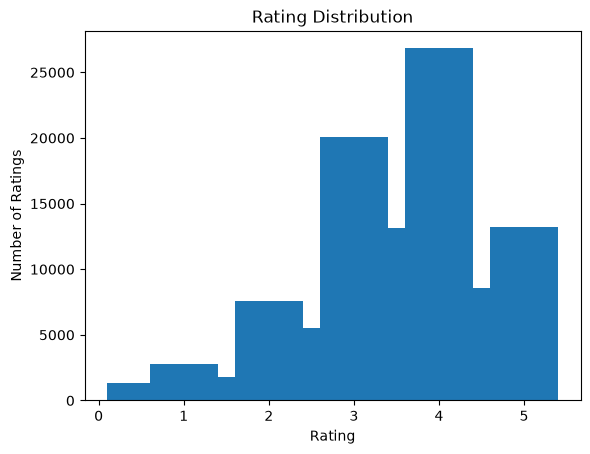

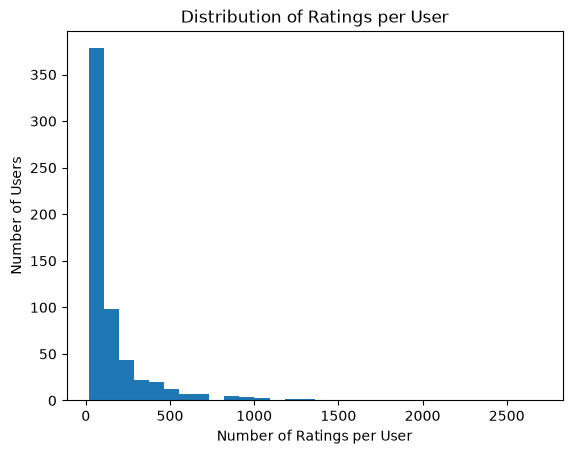

In [5]:
#bar_chart per rating (get some help from ai)
plt.bar(rating_dist.index, rating_dist.values)
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Rating Distribution")
plt.show()
#bar_chart per user
plt.hist(user_dis.values, bins=30)
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")
plt.title("Distribution of Ratings per User")
plt.show()

**What do we notice? (Part A)**

- **Ratings are skewed to the positive side.** The most common rating is 4.0 (26,818 ratings), followed by 3.0 and 5.0; only about 13% of the ratings are 2.0 or lower, and the mean rating is 3.50. Whole-star ratings are about 70% of all ratings, so users prefer whole stars to half stars.
- **Activity per user is very uneven.** Every user has at least 20 ratings (the dataset's minimum), the median user has about 70 and the mean is 165, but a few users rated thousands of movies (user 414 has 2,698). 60% of the users have 100 ratings or fewer and only 44 users have 500 or more, so the histogram has a long right tail.
- **The matrix is almost empty.** Sparsity is 98.30% (610 users x 9,724 rated movies, 100,836 ratings). About 35% of the movies have a single rating, so most pairs of users or movies have very few co-rated entries, which is why the similarity functions need a minimum number of co-rated entries.


In [6]:
def get_co_rated(matrix, a, b, axis):
    # a and b are real IDs (userId or movieId), not positions
    if axis == "index":
        first = matrix.loc[a]
        second = matrix.loc[b]
    elif axis == "columns":
        first = matrix.loc[:, a]
        second = matrix.loc[:, b]
    else:
        raise ValueError('axis must be "index" or "columns"')

    # keep only the entries where both have a rating
    mask = ~np.isnan(first) & ~np.isnan(second)
    return first[mask].values, second[mask].values


In [7]:
# Euclidean similarity
def euclidean_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    d = np.sqrt(np.sum((vec1 - vec2)**2))
    similarity = 1/(1+d)
    return similarity

# Cosine similarity
def cosine_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    denominator = np.linalg.norm(vec1) * np.linalg.norm(vec2) # ai help with linalg.norm

    if denominator == 0:
        return None

    similarity = np.dot(vec1, vec2) / denominator

    return similarity

# Pearson similarity
def pearson_similarity(vec1, vec2):
    if len(vec1) < 2:
        return None
    # Pearson is the cosine similarity of the mean-centered vectors
    vec1_centered = vec1 - np.mean(vec1)
    vec2_centered = vec2 - np.mean(vec2)
    return cosine_similarity(vec1_centered, vec2_centered)


In [8]:
# sanity check against the worked example in Section 3.2
A = np.array([5, 4, 5, 3])
B = np.array([3, 2, 3, 1])
print("Euclidean distance:  ", np.sqrt(np.sum((A - B)**2)))              # 4.0
print("Euclidean similarity:", euclidean_similarity(A, B))               # 0.2 (= 1/(1+4))
print("Cosine:              ", round(cosine_similarity(A, B), 3))        # 0.987
print("Pearson:             ", round(pearson_similarity(A, B), 3))       # 1.0


Euclidean distance:   4.0
Euclidean similarity: 0.2
Cosine:               0.987
Pearson:              1.0


In [9]:
# get_co_rated on a toy matrix whose ids are NOT 0,1,2... (like MovieLens)
toy = pd.DataFrame([[5, 4, 5, 3], [3, 2, 3, 1]], index=[10, 20], columns=[101, 102, 103, 104])
v1, v2 = get_co_rated(toy, 10, 20, "index")
print(v1, v2)                                             # [5 4 5 3] [3 2 3 1]

# get_co_rated on the real matrix: users 1 and 2 share 2 movies, users 1 and 5 share 13
v1, v2 = get_co_rated(rating_matrix, 1, 2, "index")
print(len(v1), v1, v2)
v1, v2 = get_co_rated(rating_matrix, 1, 5, "index")
print(len(v1))

# the three metrics on a real pair of users (fewer than 2 co-rated entries gives None)
print(euclidean_similarity(v1, v2), cosine_similarity(v1, v2), pearson_similarity(v1, v2))


[5 4 5 3] [3 2 3 1]
2 [5. 5.] [4. 4.]
13
0.21089672205953397 0.9707699301444195 0.26874902634577136


In [10]:
def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    scores = []
    for other_user in matrix.index:
        if other_user == target_user:
            continue  # a user is not their own neighbor

        vec1, vec2 = get_co_rated(matrix, target_user, other_user, axis="index")
        if len(vec1) < 2:
            continue  # fewer than 2 co-rated items: similarity is undefined, skip

        score = similarity_fn(vec1, vec2)
        if score is None:
            continue  # the metric could not be computed for this pair

        scores.append((other_user, score))

    scores.sort(key=lambda pair: pair[1], reverse=True)
    return scores[:k]


In [11]:
# the 5 nearest users to user 1 with each similarity metric: (user id, score)
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    nearest = find_k_nearest_users(rating_matrix, 1, 5, fn)
    print(name, [(int(user), round(float(score), 3)) for user, score in nearest])


euclidean [(77, 1.0), (278, 0.667), (472, 0.667), (511, 0.667), (550, 0.667)]


cosine [(77, 1.0), (12, 1.0), (2, 1.0), (511, 0.999), (278, 0.999)]


pearson [(146, 1.0), (106, 1.0), (333, 1.0), (550, 1.0), (598, 1.0)]


In [12]:
def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn):
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None  # unknown user or item: nothing to predict from

    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)

    numerator = 0.0
    denominator = 0.0
    for neighbor, similarity in neighbors:
        neighbor_rating = matrix.loc[neighbor, target_item]
        if np.isnan(neighbor_rating):
            continue  # this neighbor did not rate the target item
        numerator += similarity * neighbor_rating
        denominator += abs(similarity)

    if denominator == 0:
        return None  # none of the k neighbors rated the item
    return numerator / denominator


In [13]:
# predicted rating of user 1 for movie 318 with k=20 and each similarity metric
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    print(name, predict_rating_user_based(rating_matrix, 1, 318, 20, fn))


euclidean 4.7918967920028095


cosine 4.449845252882381


pearson 4.623973837700031


In [14]:
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    scores = []
    for other_item in matrix.columns:
        if other_item == target_item:
            continue  # an item is not its own neighbor

        vec1, vec2 = get_co_rated(matrix, target_item, other_item, axis="columns")
        if len(vec1) < 2:
            continue  # fewer than 2 users rated both items: similarity is undefined, skip

        score = similarity_fn(vec1, vec2)
        if score is None:
            continue  # the metric could not be computed for this pair

        scores.append((other_item, score))

    scores.sort(key=lambda pair: pair[1], reverse=True)
    return scores[:k]


In [15]:
# the 5 nearest movies to movie 318 with each similarity metric: (movie id, score)
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    nearest = find_k_nearest_items(rating_matrix, 318, 5, fn)
    print(name, [(int(item), round(float(score), 3)) for item, score in nearest])


euclidean [(132, 1.0), (715, 1.0), (1150, 1.0), (3372, 1.0), (3422, 1.0)]


cosine [(841, 1.0), (3813, 1.0), (4956, 1.0), (6184, 1.0), (8526, 1.0)]


pearson [(270, 1.0), (1971, 1.0), (1992, 1.0), (1995, 1.0), (2931, 1.0)]


In [16]:
def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None  # unknown user or item: nothing to predict from

    neighbors = find_k_nearest_items(matrix, target_item, k, similarity_fn)

    numerator = 0.0
    denominator = 0.0
    for neighbor, similarity in neighbors:
        neighbor_rating = matrix.loc[target_user, neighbor]
        if np.isnan(neighbor_rating):
            continue  # the target user did not rate this neighbor item
        numerator += similarity * neighbor_rating
        denominator += abs(similarity)

    if denominator == 0:
        return None  # the user rated none of the k neighbor items
    return numerator / denominator


In [17]:
# predicted rating of user 414 for movie 356 (real rating 5.0) with k=20, item-based, each similarity metric
for name, fn in [("euclidean", euclidean_similarity), ("cosine", cosine_similarity), ("pearson", pearson_similarity)]:
    print(name, predict_rating_item_based(rating_matrix, 414, 356, 20, fn))


euclidean 5.0


cosine 3.0


pearson 3.7777777777777777


**Part D: what was reused from Part C and what changed**

`find_k_nearest_items` and `predict_rating_item_based` follow exactly the same logic as `find_k_nearest_users` and `predict_rating_user_based`, and both rely on the same `get_co_rated` and the same three similarity functions. Only the direction changes. In `find_k_nearest_items` we loop over the columns (movies) instead of the rows (users) and call `get_co_rated` with `axis="columns"`, so two movies are compared on the users who rated both. In `predict_rating_item_based` the neighbors are movies similar to the target movie, and the weighted average uses the target user's own ratings of those neighbor movies (`matrix.loc[target_user, neighbor]`) instead of the neighbors' ratings of the target movie.


In [18]:
# AI-ASSISTED START
# split + evaluate (vectorized, same logic as Parts C and D)
def train_test_split_ratings(ratings_df, test_fraction=0.2, seed=42):
    test_df = ratings_df.groupby("userId").sample(frac=test_fraction, random_state=seed)
    train_df = ratings_df.drop(test_df.index)
    return train_df, test_df

def similarity_rows(Rz, Mf, rows, metric, min_common=2):
    Rb, Mb = Rz[rows], Mf[rows]
    n    = Mb @ Mf.T
    dot  = Rb @ Rz.T
    sq_i = (Rb**2) @ Mf.T
    sq_j = Mb @ (Rz**2).T
    with np.errstate(divide="ignore", invalid="ignore"):
        if metric == "euclidean":
            sim = 1/(1+np.sqrt(np.maximum(sq_i + sq_j - 2*dot, 0)))
        elif metric == "cosine":
            den = np.sqrt(sq_i*sq_j)
            sim = np.where(den > 0, dot/den, np.nan)
        elif metric == "pearson":
            S_i, S_j = Rb @ Mf.T, Mb @ Rz.T
            cov   = dot - S_i*S_j/n
            var_i = sq_i - S_i**2/n
            var_j = sq_j - S_j**2/n
            den = np.sqrt(np.maximum(var_i, 0)*np.maximum(var_j, 0))
            sim = np.where(den > 1e-9, cov/den, np.nan)
    sim[n < min_common] = np.nan
    sim[np.arange(len(rows)), rows] = np.nan
    return sim

def top_neighbors(X, metric, k_max=50, block=250, min_common=2):
    M  = ~np.isnan(X)
    Mf = M.astype(np.float64)
    Rz = np.where(M, X, 0.0)
    N  = X.shape[0]
    top_idx = np.zeros((N, k_max), dtype=np.int64)
    top_sim = np.full((N, k_max), np.nan)
    for start in range(0, N, block):
        rows = np.arange(start, min(start+block, N))
        sim = similarity_rows(Rz, Mf, rows, metric, min_common)
        filled = np.where(np.isnan(sim), -np.inf, sim)
        idx = np.argsort(-filled, axis=1, kind="stable")[:, :k_max]
        s = np.take_along_axis(filled, idx, axis=1)
        s[np.isneginf(s)] = np.nan
        top_idx[rows], top_sim[rows] = idx, s
    return top_idx, top_sim

SIM_NAMES = {
    euclidean_similarity: "euclidean",
    cosine_similarity: "cosine",
    pearson_similarity: "pearson",
}
_cache = {}

def evaluate(matrix, test_df, k, similarity_fn, method, min_common=2):
    metric = SIM_NAMES[similarity_fn]
    X = matrix.to_numpy() if method == "user" else matrix.to_numpy().T
    key = (method, metric, min_common)
    if key not in _cache:
        _cache[key] = top_neighbors(X, metric, 50, min_common=min_common)
    top_idx, top_sim = _cache[key]

    u_pos = matrix.index.get_indexer(test_df.userId)
    i_pos = matrix.columns.get_indexer(test_df.movieId)
    t_pos, o_pos = (u_pos, i_pos) if method == "user" else (i_pos, u_pos)
    known = (t_pos >= 0) & (o_pos >= 0)
    t, o = t_pos[known], o_pos[known]
    true = test_df.rating.to_numpy()[known]

    nb, w = top_idx[t, :k], top_sim[t, :k]
    r = X[nb, o[:, None]]
    ok = ~np.isnan(w) & ~np.isnan(r)
    num = np.where(ok, w*r, 0.0).sum(1)
    den = np.where(ok, np.abs(w), 0.0).sum(1)
    can = den > 0
    pred = num[can]/den[can]
    err = pred - true[can]
    rmse = np.sqrt(np.mean(err**2)); mae = np.mean(np.abs(err))
    none_frac = 1 - can.sum()/len(test_df)
    return rmse, mae, none_frac
# AI-ASSISTED END


In [19]:
# AI-ASSISTED START
# split, build TRAIN matrix
train_df, test_df = train_test_split_ratings(rating, test_fraction=0.2, seed=42)
train_matrix = train_df.pivot(index="userId", columns="movieId", values="rating")
_cache.clear()
print(len(train_df), len(test_df), train_df.groupby("userId").size().min())
# AI-ASSISTED END


80672 20164 16


In [20]:
# AI-ASSISTED START
# similarities of one user / one item must match your loop version exactly
for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
    name = SIM_NAMES[fn]
    ti, ts = top_neighbors(train_matrix.to_numpy(), name, k_max=20)
    loop = [s for _, s in find_k_nearest_users(train_matrix, 1, 20, fn)]
    print("user", name, np.allclose(loop, ts[train_matrix.index.get_loc(1)][:len(loop)]))
# AI-ASSISTED END


user euclidean True


user cosine True


user pearson True


In [21]:
# AI-ASSISTED START
import time
t0 = time.time()
records = []
for method in ["user", "item"]:
    for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
        for k in [5, 10, 20, 50]:
            rmse, mae, none_frac = evaluate(train_matrix, test_df, k, fn, method)
            records.append(dict(method=method, similarity=SIM_NAMES[fn], k=k,
                                RMSE=rmse, MAE=mae, frac_none=none_frac))
results = pd.DataFrame(records)
print(f"grid finished in {time.time()-t0:.0f}s")

# the full grid as one table
print(results.round(4).to_string(index=False))

# views for the analysis
print(results.pivot_table(index=["method", "similarity"], columns="k", values="RMSE").round(4))
print(results.pivot_table(index=["method", "similarity"], columns="k", values="frac_none").round(4))
print(results.loc[results.groupby(["method", "similarity"]).RMSE.idxmin()].round(4))
# AI-ASSISTED END


grid finished in 28s
method similarity  k   RMSE    MAE  frac_none
  user  euclidean  5 1.2076 0.8863     0.9122
  user  euclidean 10 1.1965 0.8900     0.8546
  user  euclidean 20 1.1791 0.8845     0.7702
  user  euclidean 50 1.1590 0.8700     0.6101
  user     cosine  5 1.2684 0.9479     0.9138
  user     cosine 10 1.2468 0.9315     0.8532
  user     cosine 20 1.2141 0.9204     0.7617
  user     cosine 50 1.1561 0.8737     0.5618
  user    pearson  5 1.3690 1.0306     0.9068
  user    pearson 10 1.3410 1.0125     0.8481
  user    pearson 20 1.2859 0.9707     0.7465
  user    pearson 50 1.1833 0.8976     0.4996
  item  euclidean  5 1.1469 0.8568     0.7212
  item  euclidean 10 1.1111 0.8289     0.6207
  item  euclidean 20 1.0806 0.8101     0.5172
  item  euclidean 50 1.0446 0.7814     0.3832
  item     cosine  5 1.2348 0.9381     0.7285
  item     cosine 10 1.1810 0.8933     0.6295
  item     cosine 20 1.1497 0.8694     0.5248
  item     cosine 50 1.1123 0.8457     0.3988
  item    pea

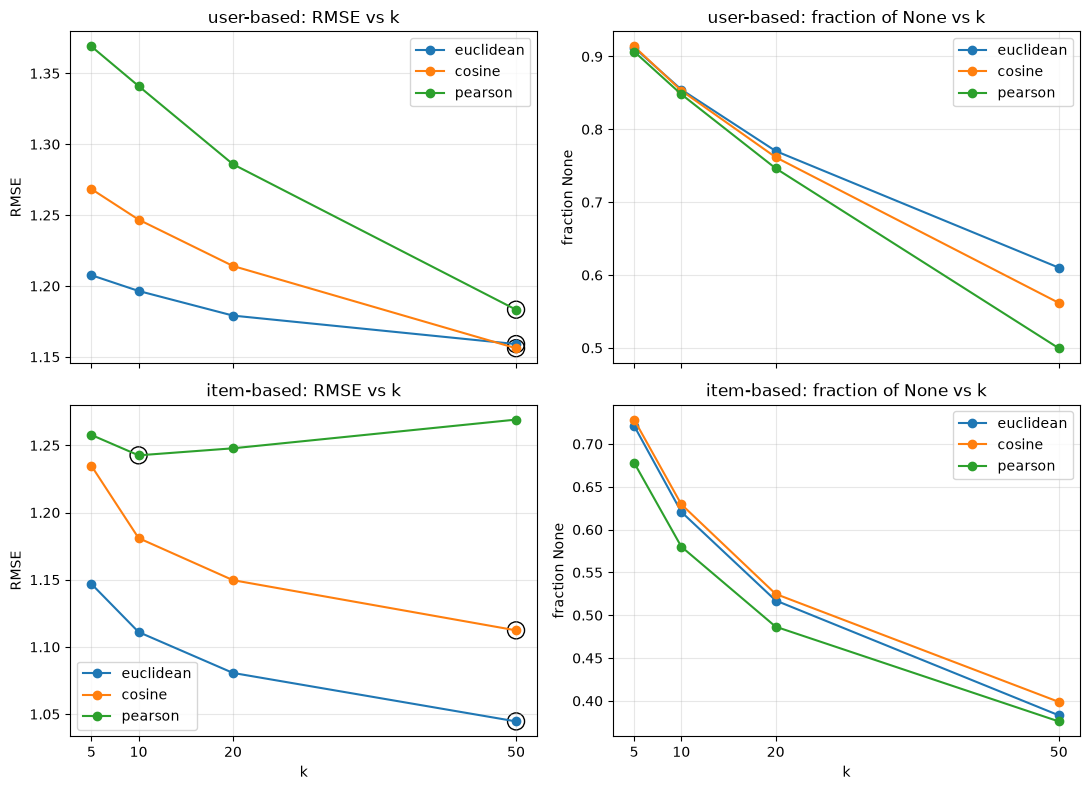

In [22]:
# AI-ASSISTED START
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for row, method in enumerate(["user", "item"]):
    for sim in ["euclidean", "cosine", "pearson"]:
        d = results[(results.method == method) & (results.similarity == sim)].sort_values("k")
        axes[row, 0].plot(d.k, d.RMSE, marker="o", label=sim)
        axes[row, 1].plot(d.k, d.frac_none, marker="o", label=sim)
        best = d.loc[d.RMSE.idxmin()]                       # circle the best k
        axes[row, 0].scatter(best.k, best.RMSE, s=150, facecolors="none", edgecolors="k")
    axes[row, 0].set_title(f"{method}-based: RMSE vs k")
    axes[row, 1].set_title(f"{method}-based: fraction of None vs k")
    axes[row, 0].set_ylabel("RMSE")
    axes[row, 1].set_ylabel("fraction None")
for ax in axes.ravel():
    ax.set_xticks(sorted(results.k.unique()))
    ax.grid(alpha=0.3)
    ax.legend()
for ax in axes[1]:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()
# AI-ASSISTED END


In [23]:
# AI-ASSISTED START
# extension: mean-centered prediction, k nearest raters, shrinkage
_cache2 = {}

def full_similarity(X, metric, shrink, min_common=2, block=250):
    M = ~np.isnan(X); Mf = M.astype(np.float64); Rz = np.where(M, X, 0.0)
    S = np.empty((len(X), len(X)), dtype=np.float32)
    for s in range(0, len(X), block):
        rows = np.arange(s, min(s + block, len(X)))
        n = Mf[rows] @ Mf.T
        S[rows] = similarity_rows(Rz, Mf, rows, metric, min_common) * n / (n + shrink)  # shrink: trust pairs with few co-rated items less
    return S

def evaluate_v2(matrix, test_df, k, similarity_fn, method, shrink=50, block=400):
    metric = SIM_NAMES[similarity_fn]
    X = matrix.to_numpy() if method == "user" else matrix.to_numpy().T
    if (method, metric, shrink) not in _cache2:
        _cache2.clear()
        _cache2[(method, metric, shrink)] = full_similarity(X, metric, shrink)
    S = _cache2[(method, metric, shrink)]
    M, mu = ~np.isnan(X), np.nanmean(X, axis=1)
    u = matrix.index.get_indexer(test_df.userId); i = matrix.columns.get_indexer(test_df.movieId)
    t, o = (u, i) if method == "user" else (i, u)
    pred = np.full(len(test_df), np.nan)
    rows = np.flatnonzero((t >= 0) & (o >= 0))
    for s in range(0, len(rows), block):
        ids = rows[s:s + block]; a, b = t[ids], o[ids]
        sims = np.where(M[:, b].T, S[a], -np.inf)           # only neighbours that rated the target item/user
        sims = np.where(np.isnan(sims), -np.inf, sims)
        idx = np.argpartition(-sims, k - 1, axis=1)[:, :k]
        w = np.take_along_axis(sims, idx, axis=1)
        w = np.where(np.isfinite(w), w, 0.0)                 # slots with no valid neighbour get weight 0
        r = np.nan_to_num(X[idx, b[:, None]] - mu[idx])      # neighbour's deviation from ITS own mean
        num = (w * r).sum(1); den = np.abs(w).sum(1)
        pred[ids] = np.where(den > 0, np.clip(mu[a] + num / np.where(den > 0, den, 1), 0.5, 5), np.nan)
    true, has = test_df.rating.to_numpy(), ~np.isnan(pred)
    user_mean = np.nanmean(matrix.to_numpy(), axis=1)
    fallback = np.where(has, pred, np.where(u >= 0, user_mean[np.maximum(u, 0)], np.nanmean(X)))
    err = pred[has] - true[has]
    return (np.sqrt(np.mean(err**2)), np.mean(np.abs(err)), 1 - has.mean(),
            np.sqrt(np.mean((fallback - true)**2)))      # last = RMSE on ALL test rows (None -> user mean)

records = []
for method in ["user", "item"]:
    for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
        for k in [5, 10, 20, 50]:
            rmse, mae, none_frac, rmse_all = evaluate_v2(train_matrix, test_df, k, fn, method)
            records.append(dict(method=method, similarity=SIM_NAMES[fn], k=k, RMSE=rmse, MAE=mae,
                                frac_none=none_frac, RMSE_all=rmse_all))
res2 = pd.DataFrame(records)
print(res2.pivot_table(index=["method", "similarity"], columns="k", values="RMSE").round(4))
print(res2.pivot_table(index=["method", "similarity"], columns="k", values="frac_none").round(4))
print(res2.loc[res2.groupby(["method", "similarity"]).RMSE.idxmin()].round(4))
# AI-ASSISTED END


k                      5       10      20      50
method similarity                                
item   cosine      0.9206  0.8952  0.8822  0.8743
       euclidean   0.8920  0.8668  0.8567  0.8576
       pearson     0.8944  0.8717  0.8651  0.8666
user   cosine      0.9502  0.9267  0.9113  0.9035
       euclidean   0.9256  0.9076  0.9024  0.9004
       pearson     0.9262  0.9037  0.8937  0.8891
k                      5       10      20      50
method similarity                                
item   cosine      0.0720  0.0720  0.0720  0.0720
       euclidean   0.0720  0.0720  0.0720  0.0720
       pearson     0.0793  0.0793  0.0793  0.0793
user   cosine      0.0394  0.0394  0.0394  0.0394
       euclidean   0.0394  0.0394  0.0394  0.0394
       pearson     0.0397  0.0397  0.0397  0.0397
   method similarity   k    RMSE     MAE  frac_none  RMSE_all
19   item     cosine  50  0.8743  0.6691     0.0720    0.8875
14   item  euclidean  20  0.8567  0.6533     0.0720    0.8714
22   item    p

In [24]:
# AI-ASSISTED START
mu = train_df.rating.mean()
um = train_df.groupby("userId").rating.mean()
print("global mean RMSE:", round(float(np.sqrt(((test_df.rating - mu) ** 2).mean())), 4))
print("user mean   RMSE:", round(float(np.sqrt(((test_df.rating - test_df.userId.map(um)) ** 2).mean())), 4))
# AI-ASSISTED END


global mean RMSE: 1.0498
user mean   RMSE: 0.9518


## Part F: Analysis and Discussion

*[AI-assisted: START]*

**Q16. Which similarity metric performed best, and does it match Section 3.2?**

Baselines (computed in Part E): predicting the global mean gives RMSE 1.050 and predicting each user's own mean gives 0.952. *Main grid* = the lab's definition (neighbors need at least 2 co-rated entries, raw weighted average of the neighbors' ratings). *Extension* = mean-centred prediction, the k nearest neighbors among those who rated the target, and shrinkage `sim*n/(n+50)`.

**Main grid.** The best configuration is item-based Euclidean with k=50 (RMSE 1.045, but 38% of the test ratings could not be predicted). For user-based the best is cosine with k=50 (1.156, 56% None). Pearson is the worst for item-based (1.24 to 1.27) and also at small k for user-based (1.37 at k=5), and no configuration beats the user-mean baseline of 0.952. This is the opposite of what Section 3.2 suggests, where Pearson should be the most reliable.

**Why.** Section 3.2 says Pearson is good at *choosing* neighbors with the same taste regardless of how harsh or generous they are. But the prediction in Section 3.5 averages the neighbors' *raw* ratings, so a harsh neighbor with Pearson close to 1 still pulls the prediction down; Euclidean picks neighbors whose absolute ratings are close, which suits a raw average. Also, Pearson on 2 or 3 co-rated entries is almost always plus or minus 1 (Parts C and D show many similarities of exactly 1.0), so many "perfect" neighbors are just noise.

**Extension.** Predicting from each neighbor's deviation from their own mean fixes this: the best Pearson RMSE drops from 1.183 to 0.889 for user-based and from 1.242 to 0.865 for item-based. User-based now agrees with Section 3.2 (Pearson 0.889, Euclidean 0.900, cosine 0.904 at k=50). Item-based is Euclidean 0.857, Pearson 0.865 and cosine 0.874; a gap of 0.008 on one split is not a real difference. The best overall is item-based Euclidean with k=20 (0.857), which beats both baselines.

**k and coverage.** In the main grid RMSE mostly falls as k grows (k=50 is best in five of six cases, so the optimum may be higher): small k is high variance, while a large k adds less similar neighbors. The exception is item-based Pearson, which is best at k=10 and gets worse after that. The fraction of None falls as k grows (user-based Pearson goes from 91% to 50%) because more neighbors means more chances that one of them rated the target, so the RMSEs of different rows cover different subsets of the test set. The extension leaves only 4% to 8% unpredictable.

**Caveat.** This is one random split, and `shrink` and k were picked by looking at the test set, so the extension numbers are slightly optimistic.

*[AI-assisted: END]*


*[AI-assisted: START]*

**Q17. Euclidean vs Pearson ranking the same users differently**

| | m1 | m2 | m3 | m4 |
|---|---|---|---|---|
| T | 4 | 5 | 4 | 5 |
| A | 5 | 4 | 5 | 4 |
| B | 1 | 2 | 1 | 2 |

- **T vs A:** differences (-1,+1,-1,+1), d = sqrt(4) = 2, Euclidean sim = 1/(1+2) = **0.333**. Both means are 4.5; the centred vectors (-.5,+.5,-.5,+.5) and (+.5,-.5,+.5,-.5) are opposite, so Pearson = **-1**.
- **T vs B:** differences (3,3,3,3), d = sqrt(36) = 6, Euclidean sim = 1/(1+6) = **0.143**. B = T - 3, so the centred vectors are identical and Pearson = **+1**.

Euclidean ranks A above B for T; Pearson ranks B above A. A is the wrong neighbour (its pattern is the reverse of T's, but its raw numbers are close), while B is a harsh rater with exactly T's taste. The pair T and A alone is the two-user version (0.333 vs -1); B is added so that a ranking exists.

*[AI-assisted: END]*


*[AI-assisted: START]*




**Q18. 200M users and 20,000 products: which is cheaper to keep up to date?**

**Item-based, by a huge margin.**
- **Pairs:** user-user 200M^2/2 = 2x10^16; item-item 20,000^2/2 = 2x10^8, i.e. 10^8 times fewer. A full float32 item matrix is about 1.6 GB and fits on one machine; the user matrix cannot be stored.
- **Per target:** 200 million comparisons for a user, 20,000 for an item.
- **Staleness:** a new rating changes one user's similarity to everyone in user-based CF, but only the pairs between that item and the user's other rated items in item-based CF. Item similarities are also stable (popular items already have thousands of ratings), so they can be recomputed offline in batches and served as precomputed top-k lists.
- **New users** get recommendations immediately from their few ratings; user-based CF would first compare them with 200 million users.
- **Caveat:** one item comparison can be longer (millions of raters) than a user comparison (tens of ratings), but this cannot offset a 10^8 difference in pairs.

This is plausibly the main reason item-based CF dominates in industry (e.g. Amazon's item-to-item approach, Linden et al., 2003). It also matches this lab, where roles were reversed: 610 users vs 9,724 movies means about 254 times more item pairs, and item-based was the slow part. The cheaper side is the one with fewer entities.

*[AI-assisted: END]*


## Bonus

In [25]:
def predict_rating_user_based_centered(matrix, target_user, target_item, k, similarity_fn):
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None  # unknown user or item: nothing to predict from

    user_means = matrix.mean(axis=1)  # each user's mean rating (NaN entries are skipped)
    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)

    numerator = 0.0
    denominator = 0.0
    for neighbor, similarity in neighbors:
        neighbor_rating = matrix.loc[neighbor, target_item]
        if np.isnan(neighbor_rating):
            continue  # this neighbor did not rate the target item
        # subtract the neighbor's own mean: only how far above/below their usual level they rated
        numerator += similarity * (neighbor_rating - user_means[neighbor])
        denominator += abs(similarity)

    if denominator == 0:
        return None  # none of the k neighbors rated the item
    # add the target user's mean back
    return user_means[target_user] + numerator / denominator


In [26]:
def evaluate_centered(matrix, test_df, k, similarity_fn, method="user", min_common=2):
    # same neighbors and same rated-by-neighbor filter as evaluate(); the only change is the mean-centering
    metric = SIM_NAMES[similarity_fn]
    X = matrix.to_numpy() if method == "user" else matrix.to_numpy().T
    key = (method, metric, min_common)
    if key not in _cache:
        _cache[key] = top_neighbors(X, metric, 50, min_common=min_common)
    top_idx, top_sim = _cache[key]
    means = np.nanmean(X, axis=1)

    u_pos = matrix.index.get_indexer(test_df.userId)
    i_pos = matrix.columns.get_indexer(test_df.movieId)
    t_pos, o_pos = (u_pos, i_pos) if method == "user" else (i_pos, u_pos)
    known = (t_pos >= 0) & (o_pos >= 0)
    t, o = t_pos[known], o_pos[known]
    true = test_df.rating.to_numpy()[known]

    nb, w = top_idx[t, :k], top_sim[t, :k]
    r = X[nb, o[:, None]]
    ok = ~np.isnan(w) & ~np.isnan(r)
    num = np.where(ok, w * (r - means[nb]), 0.0).sum(1)
    den = np.where(ok, np.abs(w), 0.0).sum(1)
    can = den > 0
    pred = means[t[can]] + num[can] / den[can]
    err = pred - true[can]
    return np.sqrt(np.mean(err**2)), np.mean(np.abs(err)), 1 - can.sum() / len(test_df)


In [27]:
# the vectorized version must agree with the loop version on a few test ratings
sample = test_df.head(15)
loop_vals, vec_check = [], []
for _, row in sample.iterrows():
    loop_vals.append(predict_rating_user_based_centered(train_matrix, row.userId, row.movieId, 20, pearson_similarity))
print("loop version, first 15 test ratings:", [None if v is None else round(float(v), 3) for v in loop_vals])
one = test_df.head(1)
print("vectorized RMSE on a single rating:", round(float(evaluate_centered(train_matrix, one, 20, pearson_similarity)[0]), 3),
      "| loop error on the same rating:",
      None if loop_vals[0] is None else round(abs(float(loop_vals[0]) - float(one.rating.iloc[0])), 3))

# plain weighted prediction vs mean-centered prediction, user-based, same neighbors
rows = []
for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
    for k in [5, 10, 20, 50]:
        p_rmse, p_mae, p_none = evaluate(train_matrix, test_df, k, fn, "user")
        c_rmse, c_mae, c_none = evaluate_centered(train_matrix, test_df, k, fn, "user")
        rows.append(dict(similarity=SIM_NAMES[fn], k=k, RMSE_plain=p_rmse, RMSE_centered=c_rmse,
                         MAE_plain=p_mae, MAE_centered=c_mae, frac_none=p_none))
bonus_table = pd.DataFrame(rows)
print(bonus_table.round(4).to_string(index=False))


loop version, first 15 test ratings: [4.897, 4.84, None, None, 4.824, None, None, 5.84, None, None, None, 5.538, None, None, None]
vectorized RMSE on a single rating: 0.103 | loop error on the same rating: 0.103


similarity  k  RMSE_plain  RMSE_centered  MAE_plain  MAE_centered  frac_none
 euclidean  5      1.2076         1.1748     0.8863        0.8989     0.9122
 euclidean 10      1.1965         1.1589     0.8900        0.8945     0.8546
 euclidean 20      1.1791         1.1470     0.8845        0.8856     0.7702
 euclidean 50      1.1590         1.1174     0.8700        0.8584     0.6101
    cosine  5      1.2684         1.2087     0.9479        0.9227     0.9138
    cosine 10      1.2468         1.1729     0.9315        0.8998     0.8532
    cosine 20      1.2141         1.1375     0.9204        0.8757     0.7617
    cosine 50      1.1561         1.0750     0.8737        0.8285     0.5618
   pearson  5      1.3690         1.2745     1.0306        0.9852     0.9068
   pearson 10      1.3410         1.2437     1.0125        0.9518     0.8481
   pearson 20      1.2859         1.1888     0.9707        0.9119     0.7465
   pearson 50      1.1833         1.0984     0.8976        0.8408     0.4996

**Bonus 1: mean-centering vs plain weighted prediction (user-based)**

`predict_rating_user_based_centered` subtracts each neighbor's mean rating, averages the deviations with the similarity weights, and adds the target user's own mean back. The loop version and the vectorized `evaluate_centered` use exactly the same neighbors and the same "rated by the neighbor" filter as the plain prediction (so the None fraction is identical); the only difference is the centering. The loop and vectorized versions agree on the checked rating (0.103 error in both).

**Result.** Mean-centering lowers the RMSE for every metric and every k: Pearson goes from 1.183 to 1.098 at k=50 (and from 1.369 to 1.275 at k=5), cosine from 1.156 to 1.075, and Euclidean from 1.159 to 1.117. The improvement is largest for cosine and Pearson and smallest for Euclidean.

**Why they are related.** Pearson similarity is the cosine of the mean-centred rating vectors, so the similarity itself already measures agreement in *deviations from the mean*. The centered prediction uses the same deviations when averaging, so the weights and the quantity being averaged match; the plain prediction weights by deviation-based similarity but averages raw ratings, which mixes a harsh neighbor's low level into the prediction. That is why the two are close but not identical: they differ exactly by the neighbors' means. The gap is not tiny here because users differ a lot in how generous they are, and because the neighbors come from very few co-rated entries.


In [28]:
def top_10_recommendations(target_user, k=50, similarity_fn=pearson_similarity, min_raters=3):
    if target_user not in rating_matrix.index:
        print("User not found.")
        return pd.DataFrame()

    # movies the user has not rated
    user_ratings = rating_matrix.loc[target_user]
    unrated_movies = user_ratings[user_ratings.isna()].index

    neighbors = find_k_nearest_users(rating_matrix, target_user, k, similarity_fn)
    neighbor_ids = [n for n, _ in neighbors]
    sims = np.array([s for _, s in neighbors])
    neighbor_ratings = rating_matrix.loc[neighbor_ids, unrated_movies].to_numpy()

    recommendations = []
    for j, movie_id in enumerate(unrated_movies):
        rated = ~np.isnan(neighbor_ratings[:, j])
        if rated.sum() < min_raters:
            continue  # a prediction from 1 or 2 neighbors is too weak to recommend
        denominator = np.abs(sims[rated]).sum()
        if denominator == 0:
            continue
        predicted = (sims[rated] * neighbor_ratings[rated, j]).sum() / denominator
        recommendations.append({"movieId": movie_id, "predicted_rating": predicted, "n_raters": int(rated.sum())})

    recommendations_df = pd.DataFrame(recommendations)
    if recommendations_df.empty:
        print("No predictions could be generated.")
        return recommendations_df

    recommendations_df = recommendations_df.merge(movie[["movieId", "title", "genres"]], on="movieId", how="left")
    recommendations_df = recommendations_df.sort_values(["predicted_rating", "n_raters"], ascending=False).head(10)
    return recommendations_df[["movieId", "title", "genres", "predicted_rating", "n_raters"]]


In [29]:
top10 = top_10_recommendations(target_user=1, k=50, similarity_fn=pearson_similarity)
top10


,movieId,title,genres,predicted_rating,n_raters
9,58,"Postman, The (Postino, Il) (1994)",Comedy|Drama|Romance,5.000000,3
57,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.831967,3
127,48516,"Departed, The (2006)",Crime|Drama|Thriller,4.790561,3
26,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.725859,17
67,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.723482,4
101,5902,Adaptation (2002),Comedy|Drama|Romance,4.719903,3
169,109487,Interstellar (2014),Sci-Fi|IMAX,4.699527,8
52,858,"Godfather, The (1972)",Crime|Drama,4.684926,5
174,116797,The Imitation Game (2014),Drama|Thriller|War,4.595301,5
180,122918,Guardians of the Galaxy 2 (2017),Action|Adventure|Sci-Fi,4.531637,3


In [30]:
# sanity check by hand: genres of the movies user 1 rated 4 or more vs genres of the 10 recommendations
from collections import Counter
liked = rating[(rating.userId == 1) & (rating.rating >= 4)].merge(movie, on="movieId")
liked_genres = Counter(g for gs in liked.genres for g in gs.split("|"))
rec_genres = Counter(g for gs in top10.genres for g in gs.split("|"))
print("user 1 rated", int((rating.userId == 1).sum()), "movies,", len(liked), "of them 4 or higher")
print("top genres in user 1's liked movies:", liked_genres.most_common(6))
print("genres in the 10 recommendations:  ", rec_genres.most_common(6))


user 1 rated 232 movies, 200 of them 4 or higher
top genres in user 1's liked movies: [('Action', 76), ('Adventure', 74), ('Comedy', 70), ('Drama', 64), ('Thriller', 43), ('Fantasy', 41)]
genres in the 10 recommendations:   [('Drama', 8), ('Crime', 4), ('Comedy', 3), ('Romance', 3), ('Thriller', 2), ('War', 2)]


**Bonus 2: sanity check of the top-10 list for user 1 (Pearson, k=50)**

Movies recommended from fewer than 3 neighbors were removed: the first version of this list gave a predicted rating of exactly 5.0 to ten obscure movies because a single neighbor with similarity near 1 had rated them.

**By hand.** User 1 rated 232 movies and 200 of them are 4 or higher, so almost everything they watch they like. Their liked movies are mostly Action (76), Adventure (74), Comedy (70) and Drama (64). The recommended list is mostly Drama (8 of 10) with Crime (4), Comedy (3) and Romance (3); only one title is Action/Adventure (Guardians of the Galaxy 2) and one is Sci-Fi (Interstellar). So Drama and Comedy match the history and Thriller appears in both, but the list leans toward acclaimed dramas (The Godfather, Shawshank Redemption, The Departed) and under-represents the Action/Adventure side of this user's taste. This is reasonable for a neighbor-based method: the neighbors' favorite movies are well-known, highly rated titles, and 5 of the 10 recommendations rest on only 3 neighbors, so the list is only moderately reliable.
